In [1]:
import torch
import torchvision
from torchvision import models

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)
print("Device:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Using CPU — we can continue.")

print("Environment ready!")


PyTorch version: 2.11.0+cu130
Torchvision version: 0.26.0+cu130
Device: cuda
GPU: Tesla T4
Environment ready!


In [2]:

import torch
import torch.nn as nn
from torchvision import models, transforms
from PIL import Image
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Load pretrained MobileNetV2
weights = models.MobileNet_V2_Weights.DEFAULT
model = models.mobilenet_v2(weights=weights)

# Freeze pretrained feature extractor
for param in model.features.parameters():
    param.requires_grad = False

# Replace the original classifier with a binary classifier
num_features = model.classifier[1].in_features

model.classifier[1] = nn.Linear(num_features, 2)
model = model.to(device)

# Image preprocessing
preprocess = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("DeepVision AI model initialized!")
print("Device:", device)
print("Output classes:", ["Normal", "Defective"])
print("Trainable parameters:", sum(
    p.numel() for p in model.parameters() if p.requires_grad
))


Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 185MB/s]


DeepVision AI model initialized!
Device: cuda
Output classes: ['Normal', 'Defective']
Trainable parameters: 2562


In [3]:

import os

print("Current directory:", os.getcwd())
print("GPU available:", torch.cuda.is_available())
print("Ready to prepare the dataset.")



Current directory: /content
GPU available: True
Ready to prepare the dataset.


In [5]:

!pip -q install anomalib


  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.0/45.0 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 33.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 246.1/246.1 kB 26.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 76.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 849.3/849.3 kB 60.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 70.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 28.4/28.4 MB 71.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.3/5.3 MB 129.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 803.9/803.9 kB 56.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 853.0/853.0 kB 62.3 MB/s eta 0:00:00


In [6]:

import os

DATA_DIR = "/content/deepvision_data"
os.makedirs(DATA_DIR, exist_ok=True)

print("Dataset directory created:", DATA_DIR)
print("Ready for dataset setup!")


Dataset directory created: /content/deepvision_data
Ready for dataset setup!


In [8]:

!pip -q install --upgrade "git+https://github.com/open-edge-platform/anomalib.git"


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [4]:

!pip -q install -U huggingface_hub
from huggingface_hub import snapshot_download
import os

DATA_DIR = "/content/deepvision_data/mvtec-ad"

print("Downloading bottle images...")

snapshot_download(
    repo_id="foersben/mvtec-ad",
    repo_type="dataset",
    local_dir=DATA_DIR,
    allow_patterns=[
        "bottle/train/**",
        "bottle/test/**",
        "bottle/ground_truth/**",
        "bottle/readme.txt",
        "bottle/license.txt",
    ],
)

print("Download finished!")
print("Bottle folder exists:", os.path.isdir(os.path.join(DATA_DIR, "bottle")))


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 839.9/839.9 kB 45.3 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
datasets 4.8.5 requires huggingface-hub<2.0,>=0.25.0, but you have huggingface-hub 2.2.0 which is incompatible.
gradio-client 2.7.1 requires huggingface-hub<2.0,>=0.19.3, but you have huggingface-hub 2.2.0 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 2.2.0 which is incompatible.
tokenizers 0.23.2 requires huggingface-hub<2.0,>=0.16.4, but you have huggingface-hub 2.2.0 which is incompatible.


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 357 files:   0%|          | 0/357 [00:00<?, ?it/s]

Download finished!
Bottle folder exists: True


In [5]:

from pathlib import Path

root = Path(DATA_DIR) / "bottle"

for split in ["train", "test", "ground_truth"]:
    folder = root / split
    print(f"\n{split}:")
    if folder.exists():
        for subfolder in sorted(folder.iterdir()):
            if subfolder.is_dir():
                count = sum(
                    1 for f in subfolder.iterdir()
                    if f.suffix.lower() in [".png", ".jpg", ".jpeg"]
                )
                print(f"  {subfolder.name}: {count} images")
    else:
        print("  Folder not found")



train:
  good: 209 images

test:
  broken_large: 20 images
  broken_small: 22 images
  contamination: 21 images
  good: 20 images

ground_truth:
  broken_large: 20 images
  broken_small: 22 images
  contamination: 21 images


In [6]:

import torch
import torch.nn.functional as F
from torchvision import models, transforms
from torch.utils.data import Dataset, DataLoader
from PIL import Image
from pathlib import Path
import numpy as np

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
root = Path(DATA_DIR) / "bottle"

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

class ImageFolderDataset(Dataset):
    def __init__(self, paths):
        self.paths = paths

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        image = Image.open(self.paths[idx]).convert("RGB")
        return transform(image), str(self.paths[idx])

train_paths = sorted((root / "train" / "good").glob("*.png"))
test_paths = sorted(
    p for p in (root / "test").rglob("*.png")
)

weights = models.MobileNet_V2_Weights.DEFAULT
backbone = models.mobilenet_v2(weights=weights).features.to(device).eval()

for param in backbone.parameters():
    param.requires_grad = False

@torch.no_grad()
def extract_features(paths):
    loader = DataLoader(
        ImageFolderDataset(paths),
        batch_size=16,
        shuffle=False,
        num_workers=2
    )
    features, names = [], []

    for images, batch_names in loader:
        images = images.to(device)
        fmap = backbone(images)
        # Each image gets a compact feature vector
        vec = F.adaptive_avg_pool2d(fmap, 1).flatten(1)
        vec = F.normalize(vec, dim=1)
        features.append(vec.cpu())
        names.extend(batch_names)

    return torch.cat(features), names

normal_features, _ = extract_features(train_paths)
test_features, test_names = extract_features(test_paths)

# Anomaly score = distance to nearest normal training feature
distances = torch.cdist(test_features, normal_features)
scores = distances.min(dim=1).values.numpy()

print("Normal training images:", len(train_paths))
print("Test images:", len(test_paths))
print("Feature bank shape:", tuple(normal_features.shape))
print("Feature extraction complete!")


Normal training images: 209
Test images: 83
Feature bank shape: (209, 1280)
Feature extraction complete!


Normal test images: 20
Defective test images: 63
Image-level ROC-AUC: 0.9992


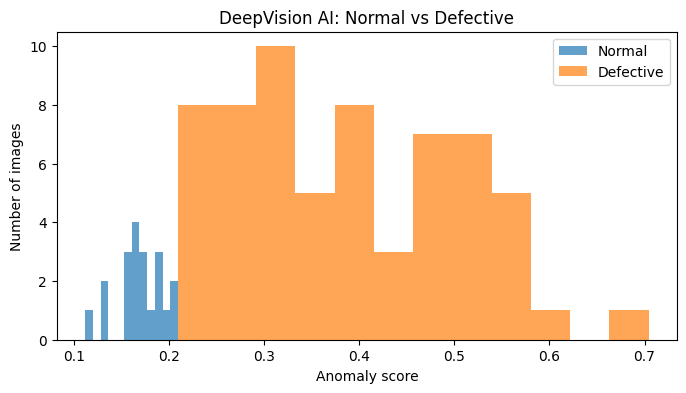

In [7]:

from sklearn.metrics import roc_auc_score
import matplotlib.pyplot as plt

labels = np.array([
    0 if Path(name).parent.name == "good" else 1
    for name in test_names
])

print("Normal test images:", int((labels == 0).sum()))
print("Defective test images:", int((labels == 1).sum()))

if len(np.unique(labels)) == 2:
    auc = roc_auc_score(labels, scores)
    print(f"Image-level ROC-AUC: {auc:.4f}")

plt.figure(figsize=(8, 4))
plt.hist(scores[labels == 0], bins=12, alpha=0.7, label="Normal")
plt.hist(scores[labels == 1], bins=12, alpha=0.7, label="Defective")
plt.xlabel("Anomaly score")
plt.ylabel("Number of images")
plt.title("DeepVision AI: Normal vs Defective")
plt.legend()
plt.show()


Prototype anomaly threshold: 0.1997
This threshold is a starting point, not a validated operating point.


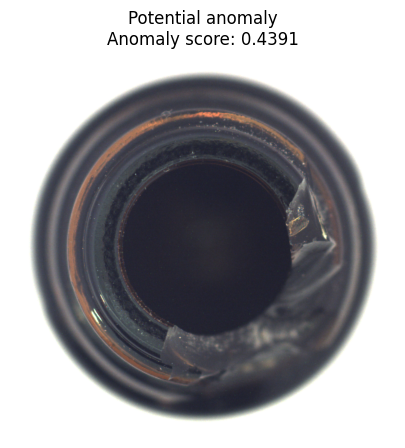

Image: 000.png
Actual test category: broken_large
Prediction: Potential anomaly
Anomaly score: 0.4391


In [8]:

import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path
import numpy as np

# Calibrate a simple threshold using normal training-image
# distances to the normal feature bank.
train_distances = torch.cdist(
    normal_features, normal_features
)
train_scores = train_distances.topk(
    k=2, largest=False, dim=1
).values[:, 1].numpy()

threshold = float(np.percentile(train_scores, 95))

print(f"Prototype anomaly threshold: {threshold:.4f}")
print("This threshold is a starting point, not a validated operating point.")

def inspect_image(index):
    path = Path(test_names[index])
    image = Image.open(path).convert("RGB")
    score = float(scores[index])

    prediction = (
        "Potential anomaly" if score > threshold else "Likely normal"
    )

    plt.figure(figsize=(6, 5))
    plt.imshow(image)
    plt.axis("off")
    plt.title(f"{prediction}\nAnomaly score: {score:.4f}")
    plt.show()

    print("Image:", path.name)
    print("Actual test category:", path.parent.name)
    print("Prediction:", prediction)
    print("Anomaly score:", round(score, 4))

inspect_image(0)


In [9]:

import gradio as gr
import numpy as np
import torch
import torch.nn.functional as F
from PIL import Image
from pathlib import Path

def predict_defect(image):
    if image is None:
        return None, "Upload an image first."

    image = image.convert("RGB")
    tensor = transform(image).unsqueeze(0).to(device)

    with torch.no_grad():
        fmap = backbone(tensor)
        vec = F.adaptive_avg_pool2d(fmap, 1).flatten(1)
        vec = F.normalize(vec, dim=1).cpu()

        score = torch.cdist(vec, normal_features).min().item()

    prediction = (
        "Potential anomaly"
        if score > threshold
        else "Likely normal"
    )

    details = (
        f"Prediction: {prediction}\n"
        f"Anomaly score: {score:.4f}\n"
        f"Threshold: {threshold:.4f}\n\n"
        "This is an experimental prototype. "
        "Predictions are not guaranteed to be correct."
    )

    return image, details

demo = gr.Interface(
    fn=predict_defect,
    inputs=gr.Image(type="pil", label="Upload a bottle image"),
    outputs=[
        gr.Image(label="Input image"),
        gr.Textbox(label="Inspection result", lines=5)
    ],
    title="DeepVision AI",
    description=(
        "Industrial visual anomaly detection using pretrained "
        "MobileNetV2 features and nearest-neighbor distance scoring."
    ),
    examples=[
        [str(p)] for p in (
            list((root / "test" / "good").glob("*.png"))[:2]
            + list((root / "test" / "broken_large").glob("*.png"))[:2]
        )
    ]
)

demo.launch(share=True)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://1946eaec968d2fff5d.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Testing image: 000.png


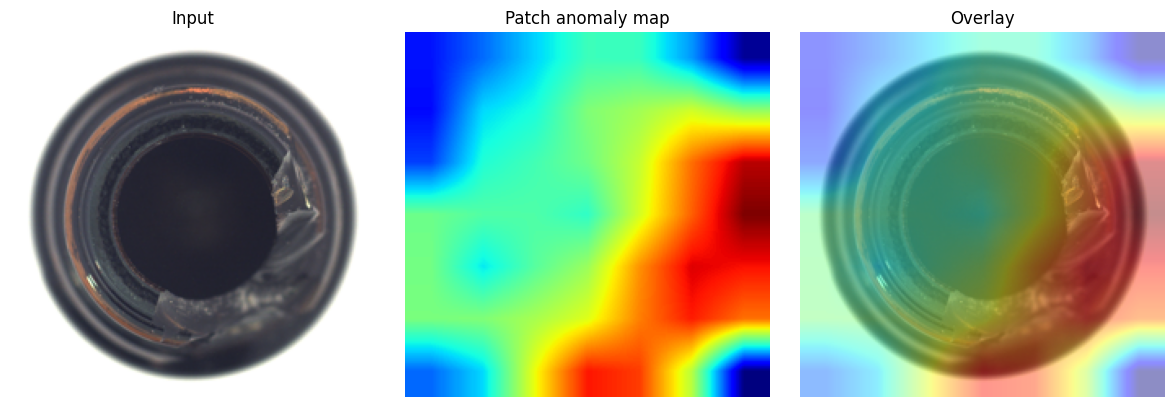

In [11]:

from pathlib import Path
from PIL import Image

# Find an actual defective test image
defect_folder = root / "test" / "broken_large"
defect_files = sorted(defect_folder.glob("*.png"))

if not defect_files:
    raise FileNotFoundError(
        f"No PNG images found in {defect_folder}"
    )

sample_image_path = defect_files[0]
sample_image = Image.open(sample_image_path).convert("RGB")

print("Testing image:", sample_image_path.name)
show_anomaly_heatmap(sample_image)


In [12]:

import os
import torch

PROJECT_DIR = "/content/DeepVision-AI"
os.makedirs(PROJECT_DIR, exist_ok=True)

artifacts = {
    "normal_features": normal_features.cpu(),
    "patch_bank": patch_bank.cpu(),
    "threshold": float(threshold),
    "image_size": 224,
    "backbone": "MobileNetV2",
    "score_method": "nearest_neighbor_cosine_feature_distance"
}

torch.save(artifacts, os.path.join(PROJECT_DIR, "deepvision_artifacts.pt"))

print("Saved project artifacts!")
print("Location:", PROJECT_DIR)
print("Artifact size (MB):", round(
    os.path.getsize(os.path.join(PROJECT_DIR, "deepvision_artifacts.pt")) / 1e6, 2
))


Saved project artifacts!
Location: /content/DeepVision-AI
Artifact size (MB): 53.51


In [13]:

%%writefile /content/DeepVision-AI/app.py
import gradio as gr
import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from torchvision import models, transforms

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
ARTIFACT_PATH = "deepvision_artifacts.pt"

artifacts = torch.load(
    ARTIFACT_PATH, map_location="cpu", weights_only=True
)
normal_features = artifacts["normal_features"].to(DEVICE)
patch_bank = artifacts["patch_bank"].to(DEVICE)
threshold = float(artifacts["threshold"])

weights = models.MobileNet_V2_Weights.DEFAULT
backbone = models.mobilenet_v2(weights=weights).features.to(DEVICE).eval()

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

@torch.no_grad()
def inspect(image):
    if image is None:
        return None, None, "Please upload an image."

    image = image.convert("RGB")
    tensor = transform(image).unsqueeze(0).to(DEVICE)

    fmap = backbone(tensor)
    vector = F.normalize(
        F.adaptive_avg_pool2d(fmap, 1).flatten(1), dim=1
    ).cpu()

    score = torch.cdist(vector, normal_features).min().item()
    result = "Potential anomaly" if score > threshold else "Likely normal"

    patches = F.normalize(
        fmap.flatten(2).transpose(1, 2), dim=-1
    ).squeeze(0)

    distances = torch.cdist(patches, patch_bank)
    patch_scores = distances.min(dim=1).values

    h, w = fmap.shape[-2:]
    heatmap = F.interpolate(
        patch_scores.reshape(1, 1, h, w),
        size=(224, 224),
        mode="bilinear",
        align_corners=False
    )[0, 0].cpu().numpy()

    heatmap = (heatmap - heatmap.min()) / (
        heatmap.max() - heatmap.min() + 1e-8
    )

    original = image.resize((224, 224))
    fig, axes = plt.subplots(1, 3, figsize=(12, 4))
    axes[0].imshow(original)
    axes[0].set_title("Input")
    axes[1].imshow(heatmap, cmap="jet")
    axes[1].set_title("Anomaly map")
    axes[2].imshow(original)
    axes[2].imshow(heatmap, cmap="jet", alpha=0.45)
    axes[2].set_title("Overlay")

    for ax in axes:
        ax.axis("off")
    fig.tight_layout()

    details = (
        f"Result: {result}\n"
        f"Anomaly score: {score:.4f}\n"
        f"Prototype threshold: {threshold:.4f}\n\n"
        "Experimental research prototype. Results are not "
        "validated for industrial decisions."
    )
    return original, fig, details

demo = gr.Interface(
    fn=inspect,
    inputs=gr.Image(type="pil", label="Upload bottle image"),
    outputs=[
        gr.Image(label="Input"),
        gr.Plot(label="Anomaly heatmap"),
        gr.Textbox(label="Inspection result", lines=5)
    ],
    title="DeepVision AI",
    description="Experimental industrial visual anomaly detection."
)

demo.launch()


Writing /content/DeepVision-AI/app.py


In [14]:

%cd /content/DeepVision-AI
!python app.py


/content/DeepVision-AI
* Running on local URL:  http://127.0.0.1:7861
* To create a public link, set `share=True` in `launch()`.
Keyboard interruption in main thread... closing server.
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/gradio/blocks.py", line 3957, in block_thread
    time.sleep(0.1)
    ~~~~~~~~~~^^^^^
KeyboardInterrupt

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "/content/DeepVision-AI/app.py", line 101, in <module>
    demo.launch()
    ~~~~~~~~~~~^^
  File "/usr/local/lib/python3.13/dist-packages/gradio/blocks.py", line 3770, in launch
    self.block_thread()
    ~~~~~~~~~~~~~~~~~^^
  File "/usr/local/lib/python3.13/dist-packages/gradio/blocks.py", line 3961, in block_thread
    self.server.close()
    ~~~~~~~~~~~~~~~~~^^
  File "/usr/local/lib/python3.13/dist-packages/gradio/http_server.py", line 82, in close
    self.thread.join(timeout=5)
    ~~~~~~~~~~~~~~~~^^^^^

In [15]:

import os

PROJECT_DIR = "/content/DeepVision-AI"

print("Project files:")
for name in sorted(os.listdir(PROJECT_DIR)):
    path = os.path.join(PROJECT_DIR, name)
    if os.path.isfile(path):
        print(f"{name} — {os.path.getsize(path) / 1024:.1f} KB")
    else:
        print(f"{name}/")


Project files:
app.py — 2.8 KB
deepvision_artifacts.pt — 52252.1 KB


In [16]:

from pathlib import Path

project = Path("/content/DeepVision-AI")
project.mkdir(exist_ok=True)

readme = """# DeepVision AI — Industrial Visual Anomaly Detection

DeepVision AI is an experimental computer-vision prototype that uses
pretrained MobileNetV2 features and nearest-neighbor distance scoring
to identify potentially anomalous bottle images.

## Features
- Pretrained CNN feature extraction with PyTorch
- Normal-image reference feature bank
- Image-level anomaly scoring
- Gradio image-upload interface
- Experimental spatial anomaly heatmap visualization

## Evaluation
Preliminary image-level ROC-AUC: 0.9992 on 83 MVTec AD bottle test images
(20 normal and 63 defective).

This result is specific to this experiment. Reproduce the evaluation and
validate the threshold before relying on it for other products or conditions.

## Run locally
1. Install dependencies: `pip install -r requirements.txt`
2. Ensure `deepvision_artifacts.pt` is in the same directory as `app.py`.
3. Run: `python app.py`

The first run may download pretrained MobileNetV2 weights.

## Dataset
MVTec Anomaly Detection (MVTec AD), bottle category:
https://www.mvtec.com/company/research/datasets/mvtec-ad

The dataset has license restrictions, including non-commercial use.
Review the original license before using the dataset or derived materials.
The dataset itself is not included in this repository.

## Limitations
This is a research prototype, not a certified industrial inspection system.
The anomaly threshold is heuristic, and heatmaps are exploratory rather than
validated defect segmentation. Performance on other products is unknown.
"""

(project / "README.md").write_text(readme, encoding="utf-8")

requirements = """torch
torchvision
gradio
numpy
matplotlib
Pillow
scikit-learn
"""

(project / "requirements.txt").write_text(requirements, encoding="utf-8")
(project / "assets").mkdir(exist_ok=True)

print("Created README.md, requirements.txt, and assets/")
print("Files:", sorted(p.name for p in project.iterdir()))


Created README.md, requirements.txt, and assets/
Files: ['README.md', 'app.py', 'assets', 'deepvision_artifacts.pt', 'requirements.txt']
